# NGT Linformer Full-Precision aligned Collide-2V workflow

Alignment points for the Meeting 29.06:

- Builds a raw per-event tensor with **5 particle features**: `pt`, `eta`, `phi`, `dxy/D0`, `pdgId/PID`.
- Computes normalization constants only from the training split.
- Builds the PID mapping only from the training split.
- Applies `preprocess_dataset(..., add_pid_ohe=True)` logic.
- Uses a full-precision PyTorch Linformer encoder similar to `linformer.py`.
- Trains on `MinBias`, `top`, `QCD`, `DY`, with `100k` events per class by default.
- Produces 1D distributions before/after preprocessing.
- Produces latent embedding plots.
- Defines anomaly score using Mahalanobis distance in PCA latent space.

NOTE:
> For quick local testing, set `N_EVENTS_PER_CLASS = 1_000`. For the NGT run, set it back to `100_000`.

In [1]:
#Just for first kernels activation
#%pip install -q numpy pandas matplotlib scikit-learn torch datasets huggingface_hub pyarrow tqdm

In [2]:
from pathlib import Path
import os
import time
import math
import json
import random
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.covariance import EmpiricalCovariance
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', DEVICE)
print('Torch:', torch.__version__)

DEVICE: cuda
Torch: 2.3.1+cu121


In [ ]:
# =========================
# Main configuration
# =========================
DATASET_ID = 'fastmachinelearning/collide-1m'

# For final NGT production run:
N_EVENTS_PER_CLASS = 100_000

# For local debugging:
#N_EVENTS_PER_CLASS = 1_000

N_CONSTITUENTS = 100
BATCH_SIZE = 512
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 4  # NGT/4-6 100k run. 0 only for Windows/PyCharm debugging.

# DY/MinBias follow-up presets. Use EXPERIMENT_PRESET='baseline_no_aug' to reproduce the 2026-07-01 run.
MODEL_PRESETS = {
    'baseline_no_aug': {
        'latent_dim': 12,
        'ff_dim': 32,
        'num_heads': 2,
        'proj_k': 8,
        'pooling_mode': 'mean',
        'use_augmentation': False,
        'augmentation_copies': 0,
    },
    'wide_no_aug': {
        'latent_dim': 24,
        'ff_dim': 64,
        'num_heads': 4,
        'proj_k': 16,
        'pooling_mode': 'mean',
        'use_augmentation': False,
        'augmentation_copies': 0,
    },
    'wide_aug': {
        'latent_dim': 24,
        'ff_dim': 64,
        'num_heads': 4,
        'proj_k': 16,
        'pooling_mode': 'mean',
        'use_augmentation': True,
        'augmentation_copies': 1,
    },
    'dy_minbias_wide_attn_aug': {
        'latent_dim': 24,
        'ff_dim': 64,
        'num_heads': 4,
        'proj_k': 16,
        'pooling_mode': 'attention',
        'use_augmentation': True,
        'augmentation_copies': 1,
    },
}

EXPERIMENT_PRESET = os.environ.get('EXPERIMENT_PRESET') or globals().get('EXPERIMENT_PRESET', 'dy_minbias_wide_attn_aug')
if EXPERIMENT_PRESET not in MODEL_PRESETS:
    raise ValueError(f'Unknown EXPERIMENT_PRESET={EXPERIMENT_PRESET!r}. Available: {sorted(MODEL_PRESETS)}')

preset = MODEL_PRESETS[EXPERIMENT_PRESET]
LATENT_DIM = preset['latent_dim']
FF_DIM = preset['ff_dim']
NUM_HEADS = preset['num_heads']
PROJ_K = preset['proj_k']
POOLING_MODE = preset['pooling_mode']
USE_AUGMENTATION = preset['use_augmentation']
AUGMENTATION_COPIES = preset['augmentation_copies']

# Raw sample for before/after preprocessing plots. Keep this much smaller than training.
RAW_SAMPLE_EVENTS_PER_CLASS = min(10_000, N_EVENTS_PER_CLASS)

# Optional DY/MinBias diagnostic using engineered event-level features.
RUN_DY_MINBIAS_DIAGNOSTIC = bool(int(os.environ.get('RUN_DY_MINBIAS_DIAGNOSTIC', '1')))
DY_MINBIAS_DIAGNOSTIC_MAX_EVENTS = min(100_000, N_EVENTS_PER_CLASS)

CLASS_NAMES = ['minbias', 'top', 'qcd', 'dy']
LABEL_MAP = {name: i for i, name in enumerate(CLASS_NAMES)}
N_CLASSES = len(CLASS_NAMES)
NORMAL_CLASS = 'minbias'
NORMAL_CLASS_IDX = LABEL_MAP[NORMAL_CLASS]

OUTPUT_ROOT = Path.cwd() / 'ngt_linformer_nodes_aligned_outputs'

# Export folders are grouped by date, then versioned per run within that date.
# runs/<YYYY-MM-DD>/<RUN_LABEL>/, where RUN_LABEL defaults to <preset>_n<events_per_class>_<HHMMSS>
# so multiple event-count experiments on the same day stay side by side and distinguishable.
RUN_DATE = time.strftime('%Y-%m-%d')
RUN_LABEL = os.environ.get('RUN_LABEL') or globals().get('RUN_LABEL')
if not RUN_LABEL:
    RUN_LABEL = f'{EXPERIMENT_PRESET}_n{N_EVENTS_PER_CLASS}_{time.strftime("%H%M%S")}'

PROJECT = OUTPUT_ROOT / 'runs' / RUN_DATE / RUN_LABEL
CACHE = OUTPUT_ROOT / 'cache'
FIGS = PROJECT / 'figures'
MODELS = PROJECT / 'models'
for pth in [OUTPUT_ROOT, PROJECT, CACHE, FIGS, MODELS]:
    pth.mkdir(parents=True, exist_ok=True)

print('OUTPUT_ROOT:', OUTPUT_ROOT)
print('RUN_DATE:', RUN_DATE)
print('RUN_LABEL:', RUN_LABEL)
print('PROJECT:', PROJECT)
print('EXPERIMENT_PRESET:', EXPERIMENT_PRESET)
print('MODEL_PRESET:', json.dumps(preset, indent=2))
print('N_EVENTS_PER_CLASS:', N_EVENTS_PER_CLASS)
print('RAW_SAMPLE_EVENTS_PER_CLASS:', RAW_SAMPLE_EVENTS_PER_CLASS)


OUTPUT_ROOT: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs
RUN_DATE: 2026-07-02
RUN_LABEL: dy_minbias_wide_attn_aug_n100000_143843
PROJECT: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843
EXPERIMENT_PRESET: dy_minbias_wide_attn_aug
MODEL_PRESET: {
  "latent_dim": 24,
  "ff_dim": 64,
  "num_heads": 4,
  "proj_k": 16,
  "pooling_mode": "attention",
  "use_augmentation": true,
  "augmentation_copies": 1
}
N_EVENTS_PER_CLASS: 100000
RAW_SAMPLE_EVENTS_PER_CLASS: 10000


## Dataset folders

The notebook streams from Hugging Face and uses the Collide-1M process folder names for Test and Optimization

In [ ]:
HF_SAMPLES = {
    'minbias': ['minbias'],
    'top': [
        'tt0123j_5f_ckm_LO_MLM_hadronic',
        'tt0123j_5f_ckm_LO_MLM_leptonic',
        'tt0123j_5f_ckm_LO_MLM_semiLeptonic',
    ],
    'qcd': ['QCD_HT50toInf', 'QCD_HT50tobb'],
    'dy': ['DYJetsToLL_13TeV-madgraphMLM-pythia8'],
}

FEATURE_SET_NAME = "l1_or_fullreco"
FEATURE_CANDIDATES = {
    "pt": [
        "L1PuppiCands_pt",
        "L1T_PFCand_PT",
        "FullReco_PUPPIPart_PT",
        "FullReco_PFCand_PT",
    ],
    "eta": [
        "L1PuppiCands_eta",
        "L1T_PFCand_Eta",
        "FullReco_PUPPIPart_Eta",
        "FullReco_PFCand_Eta",
    ],
    "phi": [
        "L1PuppiCands_phi",
        "L1T_PFCand_Phi",
        "FullReco_PUPPIPart_Phi",
        "FullReco_PFCand_Phi",
    ],
    "dxy": [
        "L1PuppiCands_dxy",
        "L1T_PFCand_D0",
        "FullReco_PUPPIPart_D0",
        "FullReco_PFCand_D0",
    ],
    "pid": [
        "L1PuppiCands_pdgId",
        "L1T_PFCand_PID",
        "FullReco_PUPPIPart_PID",
        "FullReco_PFCand_PID",
    ],
}

def log(msg: str):
    print(f'[{time.strftime("%H:%M:%S")}] {msg}', flush=True)

## `nodes.py`-aligned preprocessing functions

These functions mirror the repository logic:

- `compute_normalization_constants(raw_tensor[train_idx])`
- `build_pid_mapping(raw_tensor[train_idx])`
- `preprocess_dataset(raw_tensor, norm=norm, pid_mapping=pid_mapping, add_pid_ohe=True)`

The input raw tensor has shape:

```text
(n_events, n_constituents, 5)
```

with feature order:

```text
pt, eta, phi, dxy, pdgId/PID
```

In [5]:
def compute_normalization_constants(data: np.ndarray) -> dict:
    pt = data[:, :, 0]
    eta = data[:, :, 1]
    dxy = data[:, :, 3]

    # Match ctl2_model.utils.preprocessing exactly: include padding values in min/max.
    pt_log = np.log1p(pt)

    return {
        'pt_min': float(pt_log.min()),
        'pt_max': float(pt_log.max()),
        'eta_min': float(eta.min()),
        'eta_max': float(eta.max()),
        'phi_min': -float(np.pi),
        'phi_max': float(np.pi),
        'dxy_min': float(dxy.min()),
        'dxy_max': float(dxy.max()),
    }


def normalize_particles(x: np.ndarray, norm: dict) -> np.ndarray:
    # x[..., 0:5] = pt, eta, phi, dxy, pid
    pt_raw = x[..., 0]
    mask_pad = pt_raw == 0

    pt = np.log1p(pt_raw)
    pt = (pt - norm['pt_min']) / (norm['pt_max'] - norm['pt_min'] + 1e-8)

    eta = (x[..., 1] - norm['eta_min']) / (norm['eta_max'] - norm['eta_min'] + 1e-8)

    # Matches repository preprocessing: phi to [0, 1] using fixed [-pi, pi].
    phi = (x[..., 2] + np.pi) / (2 * np.pi)

    # Keep dxy as in repo normalize_particles: copied, not min-max normalized.
    dxy = x[..., 3].copy()
    pid = x[..., 4].copy()

    out = np.stack([pt, eta, phi, dxy, pid], axis=-1).astype(np.float32)
    out[mask_pad, :4] = 0.0
    return out


def build_pid_mapping(data: np.ndarray) -> dict:
    pid_tensor = data[:, :, 4]
    mask_valid = data[:, :, 0] > 0
    valid_pids = pid_tensor[mask_valid].astype(np.int32)
    unique_pids = np.unique(valid_pids)
    return {int(pid): idx for idx, pid in enumerate(unique_pids)}


def map_pid(pid: np.ndarray, pid_mapping: dict) -> np.ndarray:
    mapped = np.full(pid.shape, -1, dtype=np.int32)
    for k, v in pid_mapping.items():
        mapped[pid == k] = v
    return mapped


def preprocess_dataset(
    data: np.ndarray,
    norm: Optional[dict] = None,
    pid_mapping: Optional[dict] = None,
    add_pid_ohe: bool = True,
) -> Tuple[np.ndarray, dict]:
    normed = normalize_particles(data, norm)
    kine = normed[:, :, :4]

    if add_pid_ohe:
        if pid_mapping is None:
            pid_mapping = build_pid_mapping(data)
        pid = normed[:, :, 4].astype(np.int32)
        pid_idx = map_pid(pid, pid_mapping)
        n_pid_classes = len(pid_mapping)
        pid_ohe = np.zeros((*pid_idx.shape, n_pid_classes), dtype=np.float32)
        valid = pid_idx >= 0
        if n_pid_classes > 0:
            pid_ohe[valid] = np.eye(n_pid_classes, dtype=np.float32)[pid_idx[valid]]
        return np.concatenate([kine, pid_ohe], axis=-1).astype(np.float32), pid_mapping

    return normed.astype(np.float32), pid_mapping

## Streaming loader with debug logs

This loader builds exactly the raw tensor expected by the preprocessing stage. It prefers `nodes.py` L1 names, then uses L1T aliases, and finally falls back to the FullReco particle branches present in Collide-1M parquet shards.

Preferred feature mapping:

| Feature | Preferred key | L1T fallback | FullReco fallback |
|---|---|---|---|
| `pt` | `L1PuppiCands_pt` | `L1T_PFCand_PT` | `FullReco_PUPPIPart_PT`, `FullReco_PFCand_PT` |
| `eta` | `L1PuppiCands_eta` | `L1T_PFCand_Eta` | `FullReco_PUPPIPart_Eta`, `FullReco_PFCand_Eta` |
| `phi` | `L1PuppiCands_phi` | `L1T_PFCand_Phi` | `FullReco_PUPPIPart_Phi`, `FullReco_PFCand_Phi` |
| `dxy` | `L1PuppiCands_dxy` | `L1T_PFCand_D0` | `FullReco_PUPPIPart_D0`, `FullReco_PFCand_D0` |
| `pid` | `L1PuppiCands_pdgId` | `L1T_PFCand_PID` | `FullReco_PUPPIPart_PID`, `FullReco_PFCand_PID` |

The loader prints which keys were actually selected on the first event of each class.


In [6]:
def find_key(obj: dict, candidates: List[str]) -> Optional[str]:
    for k in candidates:
        if k in obj:
            return k
    return None


def extract_feature_arrays(example: dict, event_idx: int, class_name: str):
    obj = example.get('item', example)
    if not isinstance(obj, dict):
        return None

    selected = {name: find_key(obj, keys) for name, keys in FEATURE_CANDIDATES.items()}

    if event_idx == 0:
        log(f'{class_name}: first example top-level keys = {list(example.keys())[:20]}')
        log(f'{class_name}: first item keys sample = {list(obj.keys())[:80]}')
        log(f'{class_name}: selected keys = {selected}')

    if any(v is None for v in selected.values()):
        return None

    arrays = {}
    for name, key in selected.items():
        arr = np.asarray(obj[key], dtype=np.float32)
        arrays[name] = arr

    return make_event_tensor(arrays)


def make_event_tensor(arrays: dict) -> Optional[np.ndarray]:
    min_len = min(len(arrays['pt']), len(arrays['eta']), len(arrays['phi']), len(arrays['dxy']), len(arrays['pid']))
    if min_len == 0:
        return None

    n = min(min_len, N_CONSTITUENTS)
    event = np.zeros((N_CONSTITUENTS, 5), dtype=np.float32)
    event[:n, 0] = np.asarray(arrays['pt'][:n], dtype=np.float32)
    event[:n, 1] = np.asarray(arrays['eta'][:n], dtype=np.float32)
    event[:n, 2] = np.asarray(arrays['phi'][:n], dtype=np.float32)
    event[:n, 3] = np.asarray(arrays['dxy'][:n], dtype=np.float32)
    event[:n, 4] = np.asarray(arrays['pid'][:n], dtype=np.float32)
    return event


PARTICLE_COLUMN_FALLBACKS = {
    'pt': ['FullReco_PUPPIPart_PT', 'FullReco_PFCand_PT'],
    'eta': ['FullReco_PUPPIPart_Eta', 'FullReco_PFCand_Eta'],
    'phi': ['FullReco_PUPPIPart_Phi', 'FullReco_PFCand_Phi'],
    'dxy': ['FullReco_PUPPIPart_D0', 'FullReco_PFCand_D0', 'FullReco_PUPPIPart_Charge', 'FullReco_PFCand_Charge'],
    'pid': ['FullReco_PUPPIPart_PID', 'FullReco_PFCand_PID'],
}


def ensure_particle_column_fallbacks():
    global FEATURE_SET_NAME
    FEATURE_SET_NAME = 'l1_or_fullreco'
    for feature_name, fallback_names in PARTICLE_COLUMN_FALLBACKS.items():
        candidates = list(FEATURE_CANDIDATES.get(feature_name, []))
        for fallback_name in fallback_names:
            if fallback_name not in candidates:
                candidates.append(fallback_name)
        FEATURE_CANDIDATES[feature_name] = candidates


def list_hf_parquet_files(dataset_id: str, folder: str) -> List[str]:
    from huggingface_hub import HfApi

    api = HfApi()
    prefix = f'{folder.strip("/")}/'
    files = api.list_repo_files(repo_id=dataset_id, repo_type='dataset')
    return sorted(f for f in files if f.startswith(prefix) and f.endswith('.parquet'))


def selected_columns_for_parquet(available_columns) -> Optional[Dict[str, str]]:
    ensure_particle_column_fallbacks()
    available = set(available_columns)
    selected = {}
    for feature_name, candidates in FEATURE_CANDIDATES.items():
        key = next((candidate for candidate in candidates if candidate in available), None)
        if key is None:
            return None
        selected[feature_name] = key
    return selected


def stream_class_from_hf(class_name: str, target_events: int, cache_prefix: str) -> np.ndarray:
    import pyarrow as pa
    import pyarrow.parquet as pq
    from huggingface_hub import HfFileSystem

    ensure_particle_column_fallbacks()
    cache_path = CACHE / f'{cache_prefix}_{class_name}_{target_events}_{FEATURE_SET_NAME}_rawtensor.npy'
    if cache_path.exists():
        log(f'{class_name}: loading raw tensor cache {cache_path}')
        return np.load(cache_path, mmap_mode=None)

    fs = HfFileSystem()
    folders = HF_SAMPLES[class_name]
    events = []
    log('=' * 90)
    log(f'{class_name}: target={target_events:,}, candidate_folders={folders}')

    for folder in folders:
        if len(events) >= target_events:
            break

        folder_start = time.time()
        n_seen = 0
        n_valid = 0
        last_log = time.time()

        try:
            files = list_hf_parquet_files(DATASET_ID, folder)
        except Exception as exc:
            log(f'{class_name}/{folder}: could not list parquet files. Error: {repr(exc)}')
            continue

        if not files:
            log(f'{class_name}/{folder}: no parquet files found')
            continue

        log(f'{class_name}/{folder}: found {len(files):,} parquet files')

        for rel in files:
            if len(events) >= target_events:
                break

            path = f'hf://datasets/{DATASET_ID}/{rel}'
            try:
                with fs.open(path, 'rb') as fh:
                    pq_file = pq.ParquetFile(fh)
                    available_columns = list(pq_file.schema_arrow.names)
                    selected = selected_columns_for_parquet(available_columns)
                    if selected is None:
                        if n_seen == 0:
                            log(f'{class_name}/{folder}: available columns sample = {available_columns[:40]}')
                            log(f'{class_name}/{folder}: candidates = {FEATURE_CANDIDATES}')
                        log(f'{class_name}/{folder}: skipping {rel}; missing required particle columns')
                        continue

                    if n_seen == 0:
                        log(f'{class_name}/{folder}: selected keys = {selected}')

                    columns = sorted(set(selected.values()))
                    read_batch_size = int(globals().get('RAW_READ_BATCH_SIZE', 512))
                    log(f'{class_name}/{folder}: reading {rel}, columns={columns}, batch_size={read_batch_size}')
                    for batch in pq_file.iter_batches(columns=columns, batch_size=read_batch_size):
                        table = pa.Table.from_batches([batch])
                        log(f'{class_name}/{folder}: decoded batch rows={table.num_rows:,} from {rel}')
                        data = table.to_pydict()
                        for row_idx in range(table.num_rows):
                            arrays = {
                                feature_name: np.asarray(data[column_name][row_idx], dtype=np.float32)
                                for feature_name, column_name in selected.items()
                            }
                            n_seen += 1
                            event = make_event_tensor(arrays)
                            if event is not None:
                                events.append(event)
                                n_valid += 1

                            now = time.time()
                            if (n_seen % 500 == 0) or (now - last_log > 10):
                                elapsed = max(now - folder_start, 1e-6)
                                log(
                                    f'{class_name}/{folder}: seen={n_seen:,}, valid={n_valid:,}, '
                                    f'class_loaded={len(events):,}/{target_events:,}, rate={n_seen/elapsed:.1f} ev/s'
                                )
                                last_log = now

                            if len(events) >= target_events:
                                break
                        if len(events) >= target_events:
                            break
            except Exception as exc:
                log(f'{class_name}/{folder}: failed reading {rel}. Error: {repr(exc)}')
                continue

        elapsed = time.time() - folder_start
        log(f'{class_name}/{folder}: done seen={n_seen:,}, valid={n_valid:,}, elapsed={elapsed/60:.2f} min')

    if len(events) < target_events:
        raise RuntimeError(f'{class_name}: loaded only {len(events):,}/{target_events:,} events. Check HF_SAMPLES folder names and selected L1 columns.')

    raw = np.stack(events[:target_events], axis=0).astype(np.float32)
    np.save(cache_path, raw)
    log(f'{class_name}: saved raw tensor cache {cache_path}, shape={raw.shape}')
    return raw


## Load raw tensors

For the final request this loads:

```text
100k MinBias + 100k top + 100k QCD + 100k DY = 400k events
```

After that it loads from `.npy` cache.

In [7]:
raw_by_class = {}
for cls in CLASS_NAMES:
    raw_by_class[cls] = stream_class_from_hf(cls, N_EVENTS_PER_CLASS, cache_prefix='train')

raw_tensor = np.concatenate([raw_by_class[cls] for cls in CLASS_NAMES], axis=0).astype(np.float32)
y = np.concatenate([
    np.full(len(raw_by_class[cls]), LABEL_MAP[cls], dtype=np.int64)
    for cls in CLASS_NAMES
])
sample_name = np.concatenate([
    np.full(len(raw_by_class[cls]), cls, dtype=object)
    for cls in CLASS_NAMES
])

print('raw_tensor:', raw_tensor.shape, raw_tensor.dtype)
print('y:', y.shape, np.unique(y, return_counts=True))
print('sample_name:', pd.Series(sample_name).value_counts().to_dict())

[14:38:46] minbias: loading raw tensor cache /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/cache/train_minbias_100000_l1_or_fullreco_rawtensor.npy
[14:38:47] top: loading raw tensor cache /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/cache/train_top_100000_l1_or_fullreco_rawtensor.npy
[14:38:48] qcd: loading raw tensor cache /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/cache/train_qcd_100000_l1_or_fullreco_rawtensor.npy
[14:38:50] dy: loading raw tensor cache /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/cache/train_dy_100000_l1_or_fullreco_rawtensor.npy
raw_tensor: (400000, 100, 5) float32
y: (400000,) (array([0, 1, 2, 3]), array([100000, 100000, 100000, 100000]))
sample_name: {'minbias': 100000, 'top': 100000, 'qcd': 100000, 'dy': 100000}


## Plot raw 1D distributions before preprocessing

Uses the raw tensor features `pt`, `eta`, `phi`, `dxy`, `pid`.

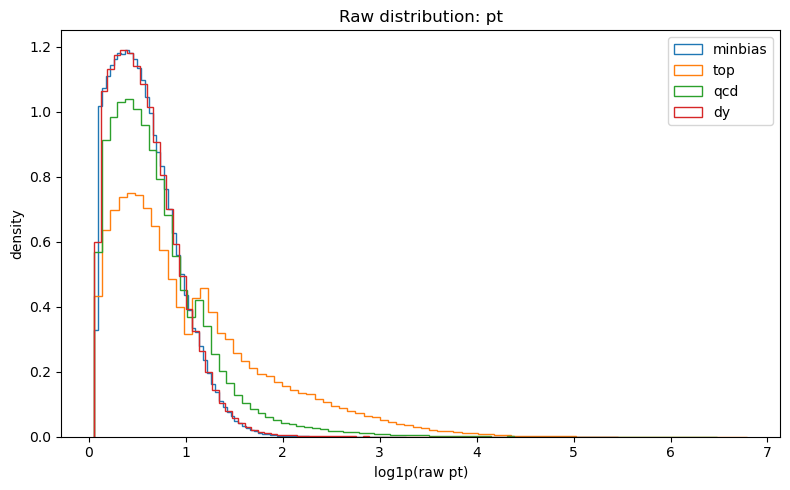

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/raw_distribution_pt.png


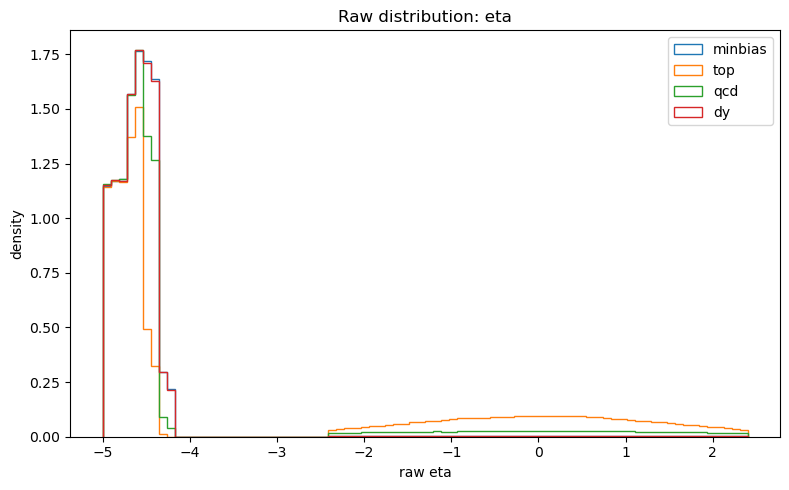

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/raw_distribution_eta.png


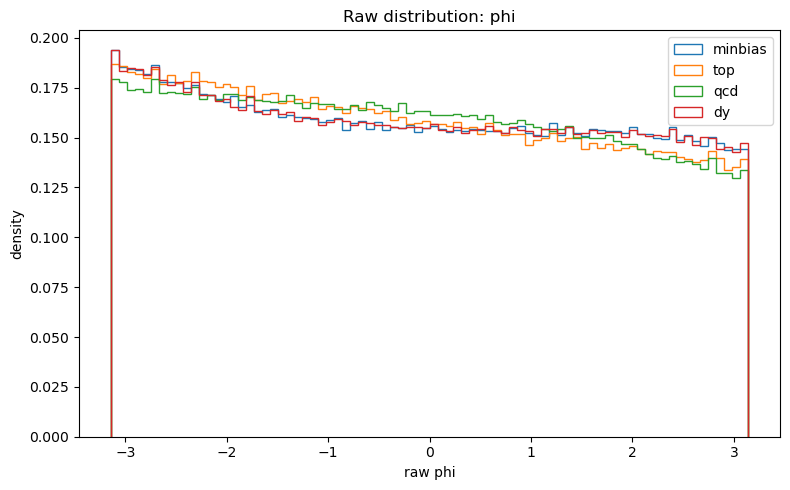

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/raw_distribution_phi.png


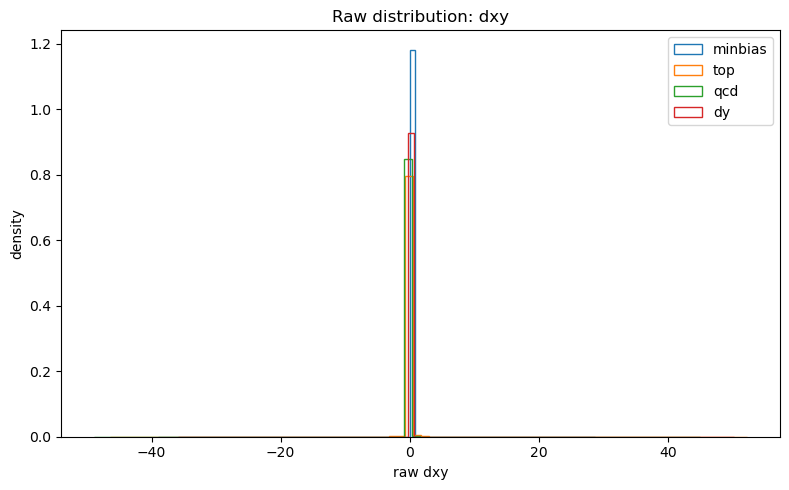

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/raw_distribution_dxy.png


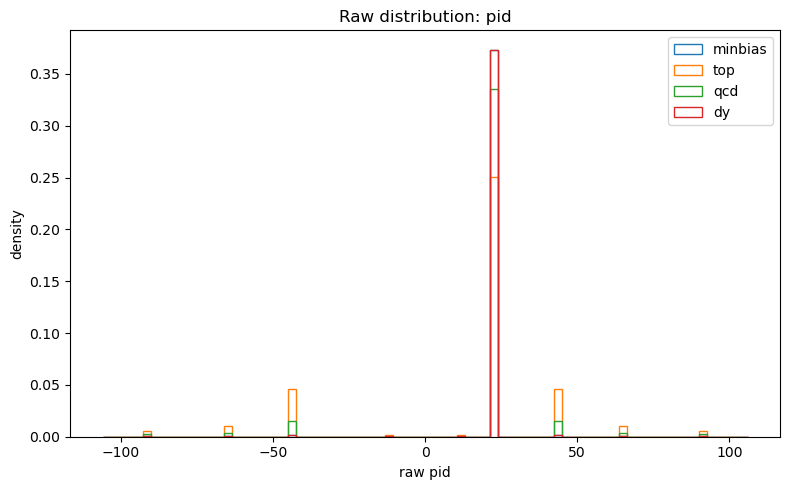

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/raw_distribution_pid.png


In [8]:
def flatten_valid_feature(raw: np.ndarray, feature_idx: int, max_events: int = 10_000):
    arr = raw[:max_events]
    mask = arr[:, :, 0] > 0
    return arr[:, :, feature_idx][mask]

FEATURE_NAMES_RAW = ['pt', 'eta', 'phi', 'dxy', 'pid']

for feat_idx, feat_name in enumerate(FEATURE_NAMES_RAW):
    plt.figure(figsize=(8, 5))
    for cls in CLASS_NAMES:
        vals = flatten_valid_feature(raw_by_class[cls], feat_idx, RAW_SAMPLE_EVENTS_PER_CLASS)
        if feat_name == 'pt':
            vals = vals[np.isfinite(vals)]
            vals = vals[vals >= 0]
            vals = np.log1p(vals)
            xlabel = 'log1p(raw pt)'
        else:
            vals = vals[np.isfinite(vals)]
            xlabel = f'raw {feat_name}'
        if len(vals) > 0:
            plt.hist(vals, bins=80, histtype='step', density=True, label=cls)
    plt.title(f'Raw distribution: {feat_name}')
    plt.xlabel(xlabel)
    plt.ylabel('density')
    plt.legend()
    plt.tight_layout()
    out = FIGS / f'raw_distribution_{feat_name}.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print('saved:', out)

## DY/MinBias input separability diagnostic

This checks whether the current L1 particle features contain an obvious DY vs MinBias discriminator before relying on the Linformer latent space. It builds event-level summaries, including lepton counts and approximate opposite-sign same-flavor lepton-pair masses, then trains a small gradient-boosted binary classifier.


              precision    recall  f1-score   support

     minbias       0.57      0.59      0.58     30000
          dy       0.57      0.55      0.56     30000

    accuracy                           0.57     60000
   macro avg       0.57      0.57      0.57     60000
weighted avg       0.57      0.57      0.57     60000

Confusion matrix:
[[17553 12447]
 [13364 16636]]
DY/MinBias event-feature ROC AUC: 0.6091


,feature,auc_drop_mean,auc_drop_std
25,n_gamma,0.021959,0.002587
22,n_lep,0.011432,0.000601
23,sum_pt_lep,0.005043,0.000511
8,mean_abs_eta,0.004951,0.000212
2,max_pt,0.003919,0.000262
9,mean_abs_dxy,0.003208,0.000432
5,pt_p75,0.003138,0.000650
13,lead4_pt,0.002579,0.000540
19,n_mu,0.002400,0.000360
1,sum_pt,0.001636,0.000858


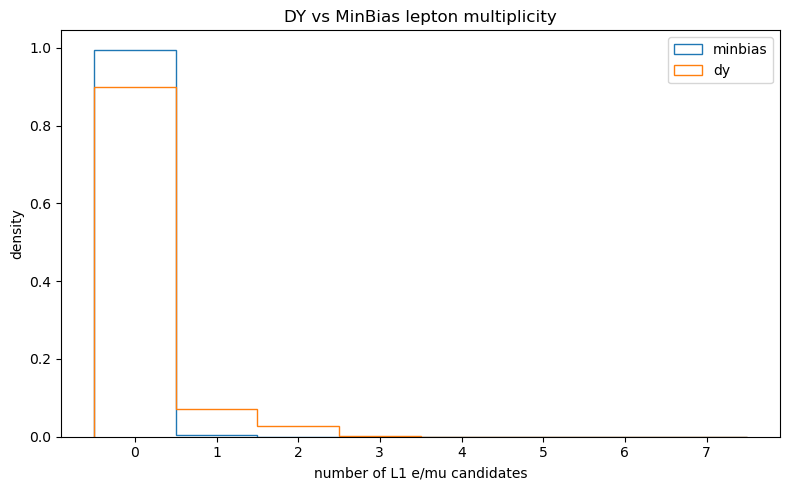

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/dy_minbias_lepton_multiplicity.png


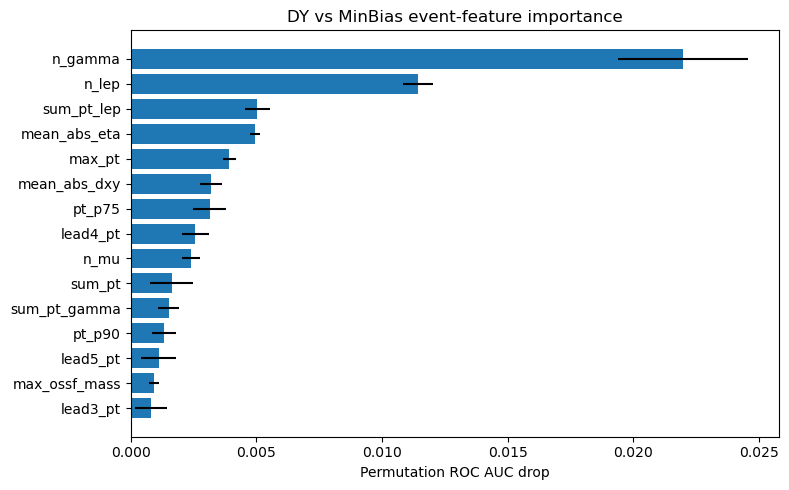

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/dy_minbias_event_feature_importance.png
Input diagnostic: DY and MinBias are weakly separable with the current L1 features, even after adding simple lepton-pair summaries.
Prioritize attention pooling / wider latent capacity, then add stronger DY observables if DY recall remains low.


In [9]:
if RUN_DY_MINBIAS_DIAGNOSTIC:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.inspection import permutation_importance
    from sklearn.metrics import roc_auc_score

    def build_dy_minbias_event_features(raw: np.ndarray) -> pd.DataFrame:
        raw = raw[:DY_MINBIAS_DIAGNOSTIC_MAX_EVENTS]
        pt = raw[:, :, 0].astype(np.float64)
        eta = raw[:, :, 1].astype(np.float64)
        phi = raw[:, :, 2].astype(np.float64)
        dxy = raw[:, :, 3].astype(np.float64)
        pid = raw[:, :, 4].astype(np.int32)
        mask = pt > 0
        n = mask.sum(axis=1).astype(np.float64)
        safe_n = np.maximum(n, 1.0)
        pt_mask = np.where(mask, pt, 0.0)
        sorted_pt = np.sort(pt_mask, axis=1)[:, ::-1]
        features = {
            'n_constituents': n,
            'sum_pt': pt_mask.sum(axis=1),
            'max_pt': pt_mask.max(axis=1),
            'mean_pt': pt_mask.sum(axis=1) / safe_n,
            'log_sum_pt': np.log1p(pt_mask.sum(axis=1)),
            'pt_p75': np.percentile(pt_mask, 75, axis=1),
            'pt_p90': np.percentile(pt_mask, 90, axis=1),
            'pt_p95': np.percentile(pt_mask, 95, axis=1),
            'mean_abs_eta': np.where(mask, np.abs(eta), 0.0).sum(axis=1) / safe_n,
            'mean_abs_dxy': np.where(mask, np.abs(dxy), 0.0).sum(axis=1) / safe_n,
        }
        for k in range(1, 7):
            features[f'lead{k}_pt'] = sorted_pt[:, k - 1]

        pid_groups = {
            'e': [11, -11],
            'mu': [13, -13],
            'lep': [11, -11, 13, -13],
            'gamma': [22],
            'ch45': [45, -45],
            'ch65': [65, -65],
            'ch92': [92, -92],
        }
        for label, values in pid_groups.items():
            group_mask = np.isin(pid, values) & mask
            features[f'n_{label}'] = group_mask.sum(axis=1).astype(np.float64)
            features[f'sum_pt_{label}'] = np.where(group_mask, pt, 0.0).sum(axis=1)
            features[f'max_pt_{label}'] = np.where(group_mask, pt, 0.0).max(axis=1)

        max_ossf_mass = np.zeros(len(raw), dtype=np.float64)
        n_ossf_pairs = np.zeros(len(raw), dtype=np.float64)
        max_ossf_pair_sum_pt = np.zeros(len(raw), dtype=np.float64)
        lepton_pids = [11, -11, 13, -13]
        for i in range(len(raw)):
            idx = np.flatnonzero(np.isin(pid[i], lepton_pids) & mask[i])
            for a in range(len(idx)):
                ia = idx[a]
                for b in range(a + 1, len(idx)):
                    ib = idx[b]
                    if pid[i, ia] + pid[i, ib] != 0:
                        continue
                    deta = eta[i, ia] - eta[i, ib]
                    dphi = (phi[i, ia] - phi[i, ib] + np.pi) % (2 * np.pi) - np.pi
                    mass2 = 2 * pt[i, ia] * pt[i, ib] * (np.cosh(deta) - np.cos(dphi))
                    mass = np.sqrt(max(float(mass2), 0.0))
                    n_ossf_pairs[i] += 1
                    max_ossf_mass[i] = max(max_ossf_mass[i], mass)
                    max_ossf_pair_sum_pt[i] = max(max_ossf_pair_sum_pt[i], pt[i, ia] + pt[i, ib])
        features['n_ossf_lepton_pairs'] = n_ossf_pairs
        features['max_ossf_mass'] = max_ossf_mass
        features['max_ossf_pair_sum_pt'] = max_ossf_pair_sum_pt
        return pd.DataFrame(features)

    X_mb_diag = build_dy_minbias_event_features(raw_by_class['minbias'])
    X_dy_diag = build_dy_minbias_event_features(raw_by_class['dy'])
    X_diag = pd.concat([X_mb_diag, X_dy_diag], ignore_index=True)
    y_diag = np.r_[np.zeros(len(X_mb_diag), dtype=np.int64), np.ones(len(X_dy_diag), dtype=np.int64)]
    X_diag_train, X_diag_eval, y_diag_train, y_diag_eval = train_test_split(
        X_diag,
        y_diag,
        test_size=0.30,
        random_state=SEED,
        stratify=y_diag,
    )
    dy_mb_clf = HistGradientBoostingClassifier(
        max_iter=160,
        learning_rate=0.07,
        max_leaf_nodes=31,
        l2_regularization=1e-3,
        random_state=SEED,
    )
    dy_mb_clf.fit(X_diag_train, y_diag_train)
    dy_mb_proba = dy_mb_clf.predict_proba(X_diag_eval)[:, 1]
    dy_mb_pred = (dy_mb_proba >= 0.5).astype(np.int64)
    dy_mb_auc = roc_auc_score(y_diag_eval, dy_mb_proba)
    print(classification_report(y_diag_eval, dy_mb_pred, target_names=['minbias', 'dy']))
    print('Confusion matrix:')
    print(confusion_matrix(y_diag_eval, dy_mb_pred))
    print(f'DY/MinBias event-feature ROC AUC: {dy_mb_auc:.4f}')

    pd.DataFrame(classification_report(y_diag_eval, dy_mb_pred, target_names=['minbias', 'dy'], output_dict=True)).T.to_csv(
        PROJECT / 'dy_minbias_event_classifier_report.csv'
    )
    pd.DataFrame(
        confusion_matrix(y_diag_eval, dy_mb_pred),
        index=['true_minbias', 'true_dy'],
        columns=['pred_minbias', 'pred_dy'],
    ).to_csv(PROJECT / 'dy_minbias_event_classifier_confusion.csv')

    perm = permutation_importance(
        dy_mb_clf,
        X_diag_eval,
        y_diag_eval,
        n_repeats=3,
        random_state=SEED,
        n_jobs=1,
        scoring='roc_auc',
    )
    feature_importance = pd.DataFrame({
        'feature': X_diag.columns,
        'auc_drop_mean': perm.importances_mean,
        'auc_drop_std': perm.importances_std,
    }).sort_values('auc_drop_mean', ascending=False)
    feature_importance.to_csv(PROJECT / 'dy_minbias_event_feature_importance.csv', index=False)
    display(feature_importance.head(15))

    summary_blocks = []
    for cls, frame in [('minbias', X_mb_diag), ('dy', X_dy_diag)]:
        desc = frame.describe(percentiles=[0.10, 0.50, 0.90, 0.95, 0.99]).T.reset_index().rename(columns={'index': 'feature'})
        desc.insert(0, 'class', cls)
        summary_blocks.append(desc)
    pd.concat(summary_blocks, ignore_index=True).to_csv(PROJECT / 'dy_minbias_event_feature_summary.csv', index=False)

    plt.figure(figsize=(8, 5))
    for cls, frame in [('minbias', X_mb_diag), ('dy', X_dy_diag)]:
        plt.hist(frame['n_lep'], bins=np.arange(-0.5, 8.5, 1), histtype='step', density=True, label=cls)
    plt.xlabel('number of L1 e/mu candidates')
    plt.ylabel('density')
    plt.title('DY vs MinBias lepton multiplicity')
    plt.legend()
    plt.tight_layout()
    out = FIGS / 'dy_minbias_lepton_multiplicity.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print('saved:', out)

    plt.figure(figsize=(8, 5))
    top_features = feature_importance.head(15).iloc[::-1]
    plt.barh(top_features['feature'], top_features['auc_drop_mean'], xerr=top_features['auc_drop_std'])
    plt.xlabel('Permutation ROC AUC drop')
    plt.title('DY vs MinBias event-feature importance')
    plt.tight_layout()
    out = FIGS / 'dy_minbias_event_feature_importance.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print('saved:', out)

    if dy_mb_auc < 0.70:
        print('Input diagnostic: DY and MinBias are weakly separable with the current L1 features, even after adding simple lepton-pair summaries.')
        print('Prioritize attention pooling / wider latent capacity, then add stronger DY observables if DY recall remains low.')
else:
    print('DY/MinBias diagnostic disabled.')


## Split like `nodes.py`, then preprocess

This follows the `nodes.py` order:

1. create train/val/eval indices,
2. compute normalization constants from `raw_tensor[train_idx]`,
3. build PID mapping from `raw_tensor[train_idx]`,
4. preprocess all data with `add_pid_ohe=True`,
5. return `X_train`, `X_aug`, `X_val`, `X_eval`.

In [10]:
all_idx = np.arange(len(raw_tensor))
train_idx, temp_idx = train_test_split(
    all_idx,
    test_size=0.30,
    random_state=SEED,
    stratify=y,
)
val_idx, eval_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=y[temp_idx],
)

norm = compute_normalization_constants(raw_tensor[train_idx])
pid_mapping = build_pid_mapping(raw_tensor[train_idx])
X_all, pid_mapping = preprocess_dataset(
    raw_tensor,
    norm=norm,
    pid_mapping=pid_mapping,
    add_pid_ohe=True,
)

X_train = X_all[train_idx]
y_train = y[train_idx]
X_val = X_all[val_idx]
y_val = y[val_idx]
X_eval = X_all[eval_idx]
y_eval = y[eval_idx]

print('norm:', json.dumps(norm, indent=2))
print('pid_mapping:', pid_mapping)
print('X_all:', X_all.shape, X_all.dtype)
print('X_train:', X_train.shape, y_train.shape)
print('X_val:', X_val.shape, y_val.shape)
print('X_eval:', X_eval.shape, y_eval.shape)
print('n_features after PID OHE:', X_all.shape[-1])

norm: {
  "pt_min": 0.05121699720621109,
  "pt_max": 7.167809009552002,
  "eta_min": -5.0,
  "eta_max": 2.400390625,
  "phi_min": -3.141592653589793,
  "phi_max": 3.141592653589793,
  "dxy_min": -51.86589431762695,
  "dxy_max": 51.23981857299805
}
pid_mapping: {-106: 0, -92: 1, -65: 2, -45: 3, -40: 4, -16: 5, -13: 6, -11: 7, -6: 8, 6: 9, 11: 10, 13: 11, 16: 12, 22: 13, 40: 14, 45: 15, 65: 16, 92: 17, 106: 18}
X_all: (400000, 100, 23) float32
X_train: (280000, 100, 23) (280000,)
X_val: (60000, 100, 23) (60000,)
X_eval: (60000, 100, 23) (60000,)
n_features after PID OHE: 23


## Optional simple augmentation producing `X_aug`

`nodes.py` can create `X_aug` using `GSEALAugmentation`, then preprocesses augmented raw tensors with the same `norm` and `pid_mapping`.

This notebook provides a lightweight optional augmentation: random rotation in `phi`. It preserves the same interface and preprocessing order. Keep it disabled for the first baseline.

In [11]:
def augment_rotate_phi(raw: np.ndarray, max_rotation: float = np.pi) -> np.ndarray:
    aug = raw.copy()
    angles = np.random.uniform(-max_rotation, max_rotation, size=(len(raw), 1)).astype(np.float32)
    mask = aug[:, :, 0] > 0
    aug[:, :, 2] = ((aug[:, :, 2] + angles + np.pi) % (2 * np.pi)) - np.pi
    aug[~mask, 2] = 0.0
    return aug

if USE_AUGMENTATION:
    augmented_blocks = [X_train]
    for copy_idx in range(AUGMENTATION_COPIES):
        raw_aug_train = augment_rotate_phi(raw_tensor[train_idx])
        X_rot, _ = preprocess_dataset(raw_aug_train, norm=norm, pid_mapping=pid_mapping, add_pid_ohe=True)
        augmented_blocks.append(X_rot)
    X_aug = np.concatenate(augmented_blocks, axis=0)
    y_aug = np.tile(y_train, AUGMENTATION_COPIES + 1)
    print(f'Using phi-rotation augmentation: original + {AUGMENTATION_COPIES} rotated copies -> {X_aug.shape}')
else:
    X_aug = X_train.copy()
    y_aug = y_train.copy()
    print('Augmentation disabled. X_aug = X_train copy:', X_aug.shape)


Using phi-rotation augmentation: original + 1 rotated copies -> (560000, 100, 23)


## Plot 1D distributions after preprocessing

The first 4 features are kinematics:

```text
pt_norm, eta_norm, phi_norm, dxy
```

The remaining features are PID one-hot entries.

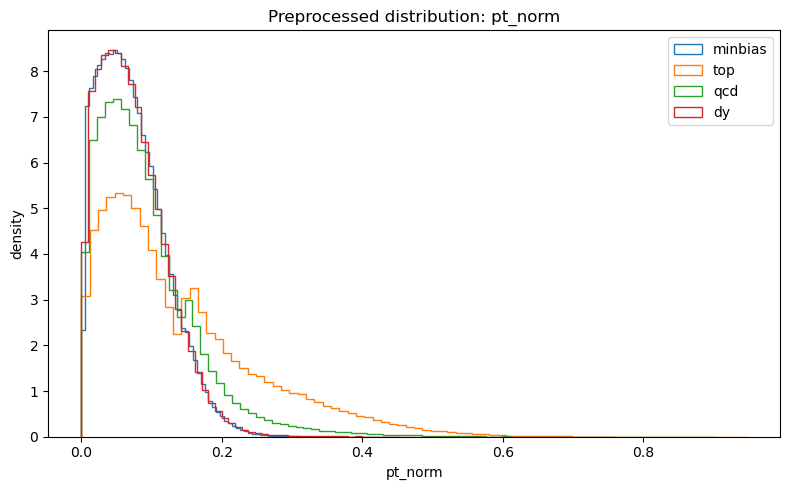

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/preprocessed_distribution_pt_norm.png


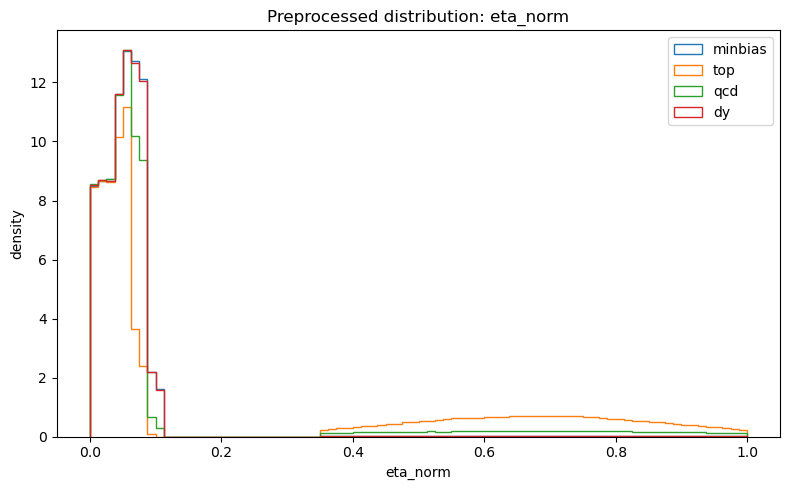

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/preprocessed_distribution_eta_norm.png


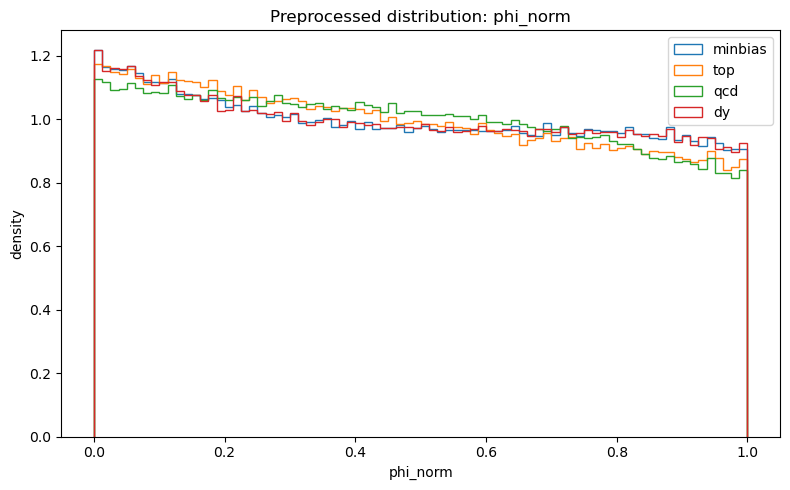

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/preprocessed_distribution_phi_norm.png


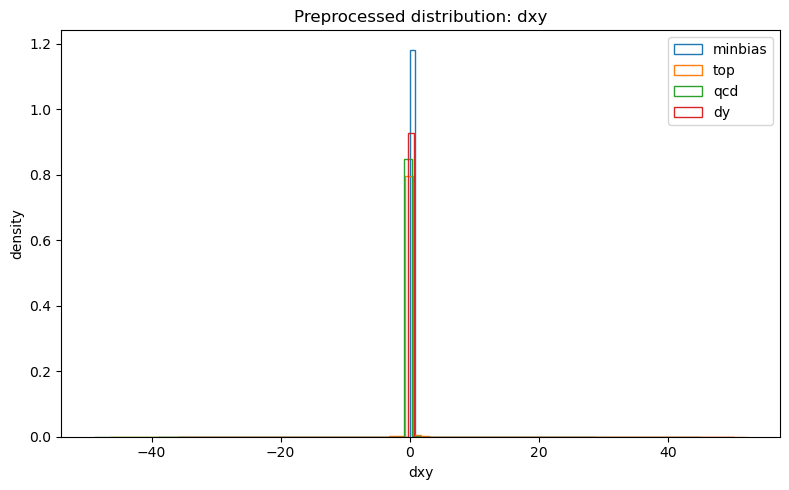

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/preprocessed_distribution_dxy.png
PID counts: {-106: 2233, -92: 219522, -65: 391420, -45: 1679727, -40: 2063, -16: 784, -13: 27624, -11: 23953, -6: 35, 6: 31, 11: 24313, 13: 27413, 16: 672, 22: 35311712, 40: 2112, 45: 1674102, 65: 392171, 92: 217851, 106: 2262}


In [12]:
FEATURE_NAMES_PRE = ['pt_norm', 'eta_norm', 'phi_norm', 'dxy']

for feat_idx, feat_name in enumerate(FEATURE_NAMES_PRE):
    plt.figure(figsize=(8, 5))
    for cls in CLASS_NAMES:
        cls_mask = y == LABEL_MAP[cls]
        arr = X_all[cls_mask][:RAW_SAMPLE_EVENTS_PER_CLASS]
        valid = arr[:, :, 0] > 0
        vals = arr[:, :, feat_idx][valid]
        vals = vals[np.isfinite(vals)]
        if len(vals) > 0:
            plt.hist(vals, bins=80, histtype='step', density=True, label=cls)
    plt.title(f'Preprocessed distribution: {feat_name}')
    plt.xlabel(feat_name)
    plt.ylabel('density')
    plt.legend()
    plt.tight_layout()
    out = FIGS / f'preprocessed_distribution_{feat_name}.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print('saved:', out)

# PID distribution after mapping
pid_counts = {}
for pid, idx in pid_mapping.items():
    pid_counts[pid] = int((raw_tensor[:, :, 4][raw_tensor[:, :, 0] > 0].astype(np.int32) == pid).sum())
print('PID counts:', pid_counts)

# Full-precision PyTorch Linformer model

This is the dense PyTorch analogue of `linformer.py`:

| Original HGQ/Keras layer | PyTorch full precision equivalent |
|---|---|
| `QDense` | `nn.Linear` |
| `QAdd` | `+` residual add |
| `QSum(axes=1) / N` | `sum(dim=1) / N` |
| `QLinformerAttention` | dense PyTorch Linformer attention |
| softmax output | logits + `CrossEntropyLoss` |

In [13]:
class LinformerAttention(nn.Module):
    def __init__(self, dim: int, num_heads: int = 2, proj_k: int = 8, seq_len: int = 100, dropout: float = 0.0):
        super().__init__()
        assert dim % num_heads == 0, 'dim must be divisible by num_heads'
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.seq_len = seq_len
        self.proj_k = proj_k

        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim)

        # Linformer sequence projection E/F: N -> proj_k.
        self.E = nn.Parameter(torch.randn(num_heads, proj_k, seq_len) * 0.02)
        self.F = nn.Parameter(torch.randn(num_heads, proj_k, seq_len) * 0.02)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: [B, N, D]
        B, N, D = x.shape
        q = self.q_proj(x).view(B, N, self.num_heads, self.head_dim).transpose(1, 2)  # [B,H,N,d]
        k = self.k_proj(x).view(B, N, self.num_heads, self.head_dim).transpose(1, 2)  # [B,H,N,d]
        v = self.v_proj(x).view(B, N, self.num_heads, self.head_dim).transpose(1, 2)  # [B,H,N,d]

        E = self.E[:, :, :N]
        Fp = self.F[:, :, :N]
        k_proj = torch.einsum('hkn,bhnd->bhkd', E, k)   # [B,H,K,d]
        v_proj = torch.einsum('hkn,bhnd->bhkd', Fp, v)  # [B,H,K,d]

        scores = torch.matmul(q, k_proj.transpose(-2, -1)) / math.sqrt(self.head_dim)  # [B,H,N,K]
        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)
        out = torch.matmul(attn, v_proj)  # [B,H,N,d]
        out = out.transpose(1, 2).contiguous().view(B, N, D)
        return self.out_proj(out)


class LinformerEmbeddingFullPrecision(nn.Module):
    def __init__(
        self,
        n_constituents: int,
        n_features: int,
        latent_dim: int,
        n_classes: int,
        ff_dim: int = 32,
        num_heads: int = 2,
        proj_k: int = 8,
        pooling_mode: str = 'mean',
    ):
        super().__init__()
        assert pooling_mode in {'mean', 'attention'}
        self.n_constituents = n_constituents
        self.pooling_mode = pooling_mode
        self.input_proj = nn.Linear(n_features, ff_dim)
        self.attention1 = LinformerAttention(ff_dim, num_heads=num_heads, proj_k=proj_k, seq_len=n_constituents)
        self.attention2 = LinformerAttention(ff_dim, num_heads=num_heads, proj_k=proj_k, seq_len=n_constituents)
        if pooling_mode == 'attention':
            pool_hidden = max(8, ff_dim // 2)
            self.pool_score = nn.Sequential(
                nn.Linear(ff_dim, pool_hidden),
                nn.ReLU(),
                nn.Linear(pool_hidden, 1),
            )
        else:
            self.pool_score = None
        self.post_pool = nn.Sequential(
            nn.Linear(ff_dim, ff_dim),
            nn.ReLU(),
            nn.Linear(ff_dim, ff_dim),
            nn.ReLU(),
        )
        self.latent = nn.Linear(ff_dim, latent_dim)
        self.cls_hidden = nn.Sequential(
            nn.Linear(latent_dim, ff_dim),
            nn.ReLU(),
        )
        self.class_logits = nn.Linear(ff_dim, n_classes)

    def pool(self, res, valid_mask):
        valid_float = valid_mask.unsqueeze(-1).to(res.dtype)
        if self.pooling_mode == 'mean':
            denom = valid_float.sum(dim=1).clamp_min(1.0)
            return (res * valid_float).sum(dim=1) / denom

        scores = self.pool_score(res).squeeze(-1)
        scores = scores.masked_fill(~valid_mask, -1e9)
        weights = torch.softmax(scores, dim=1) * valid_mask.to(res.dtype)
        weights = weights / weights.sum(dim=1, keepdim=True).clamp_min(1e-6)
        return (res * weights.unsqueeze(-1)).sum(dim=1)

    def forward(self, x):
        valid_mask = torch.any(x != 0, dim=-1)
        emb = F.relu(self.input_proj(x))
        x1 = self.attention1(emb)
        res = x1 + emb
        x2 = self.attention2(res)
        res = x2 + res
        pooled = self.pool(res, valid_mask)
        h = self.post_pool(pooled)
        z = self.latent(h)
        logits = self.class_logits(self.cls_hidden(z))
        return {'latent': z, 'logits': logits}

model = LinformerEmbeddingFullPrecision(
    n_constituents=N_CONSTITUENTS,
    n_features=X_train.shape[-1],
    latent_dim=LATENT_DIM,
    n_classes=N_CLASSES,
    ff_dim=FF_DIM,
    num_heads=NUM_HEADS,
    proj_k=PROJ_K,
    pooling_mode=POOLING_MODE,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
print(model)
print('parameters:', n_params)


LinformerEmbeddingFullPrecision(
  (input_proj): Linear(in_features=23, out_features=64, bias=True)
  (attention1): LinformerAttention(
    (q_proj): Linear(in_features=64, out_features=64, bias=True)
    (k_proj): Linear(in_features=64, out_features=64, bias=True)
    (v_proj): Linear(in_features=64, out_features=64, bias=True)
    (out_proj): Linear(in_features=64, out_features=64, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (attention2): LinformerAttention(
    (q_proj): Linear(in_features=64, out_features=64, bias=True)
    (k_proj): Linear(in_features=64, out_features=64, bias=True)
    (v_proj): Linear(in_features=64, out_features=64, bias=True)
    (out_proj): Linear(in_features=64, out_features=64, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (pool_score): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
  (post_pool): Sequential(
    (0): Lin

## Training

This trains the classifier head using `CrossEntropyLoss` and uses the `latent` output as the embedding space. The model remains full precision.

In [14]:
class TensorDatasetTorch(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.from_numpy(X.astype(np.float32))
        self.y = torch.from_numpy(y.astype(np.int64))
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(
    TensorDatasetTorch(X_aug, y_aug),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    TensorDatasetTorch(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss = 0.0
    total_correct = 0
    total = 0

    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        with torch.set_grad_enabled(is_train):
            out = model(xb)
            loss = F.cross_entropy(out['logits'], yb)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

        total_loss += float(loss.item()) * len(xb)
        pred = out['logits'].argmax(dim=1)
        total_correct += int((pred == yb).sum().item())
        total += len(xb)

    return total_loss / max(total, 1), total_correct / max(total, 1)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
best_val_loss = float('inf')
history = []

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = run_epoch(model, train_loader, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, optimizer=None)
    elapsed = time.time() - t0

    row = {
        'epoch': epoch,
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_acc': val_acc,
        'elapsed_s': elapsed,
    }
    history.append(row)
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | {elapsed:.1f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            'model_state_dict': model.state_dict(),
            'config': {
                'experiment_preset': EXPERIMENT_PRESET,
                'n_constituents': N_CONSTITUENTS,
                'n_features': X_train.shape[-1],
                'latent_dim': LATENT_DIM,
                'n_classes': N_CLASSES,
                'ff_dim': FF_DIM,
                'num_heads': NUM_HEADS,
                'proj_k': PROJ_K,
                'pooling_mode': POOLING_MODE,
                'use_augmentation': USE_AUGMENTATION,
                'augmentation_copies': AUGMENTATION_COPIES,
                'pid_mapping': pid_mapping,
                'norm': norm,
                'class_names': CLASS_NAMES,
            },
        }, MODELS / 'linformer_nodes_aligned_best.pt')

pd.DataFrame(history).to_csv(PROJECT / 'training_history.csv', index=False)
print('saved model:', MODELS / 'linformer_nodes_aligned_best.pt')


Epoch 001/30 | train_loss=0.6882 train_acc=0.6452 | val_loss=0.6240 val_acc=0.6743 | 9.7s
Epoch 002/30 | train_loss=0.6166 train_acc=0.6788 | val_loss=0.6073 val_acc=0.6809 | 11.9s
Epoch 003/30 | train_loss=0.5940 train_acc=0.6902 | val_loss=0.5909 val_acc=0.6924 | 12.0s
Epoch 004/30 | train_loss=0.5839 train_acc=0.6951 | val_loss=0.5756 val_acc=0.6945 | 12.5s
Epoch 005/30 | train_loss=0.5777 train_acc=0.6977 | val_loss=0.5701 val_acc=0.7027 | 9.5s
Epoch 006/30 | train_loss=0.5731 train_acc=0.6994 | val_loss=0.5669 val_acc=0.7040 | 8.0s
Epoch 007/30 | train_loss=0.5703 train_acc=0.7003 | val_loss=0.5664 val_acc=0.7040 | 6.5s
Epoch 008/30 | train_loss=0.5695 train_acc=0.7007 | val_loss=0.5659 val_acc=0.7046 | 10.1s
Epoch 009/30 | train_loss=0.5674 train_acc=0.7020 | val_loss=0.5707 val_acc=0.6980 | 8.0s
Epoch 010/30 | train_loss=0.5655 train_acc=0.7026 | val_loss=0.5670 val_acc=0.7045 | 9.2s
Epoch 011/30 | train_loss=0.5625 train_acc=0.7042 | val_loss=0.5649 val_acc=0.7045 | 11.3s
Epoch

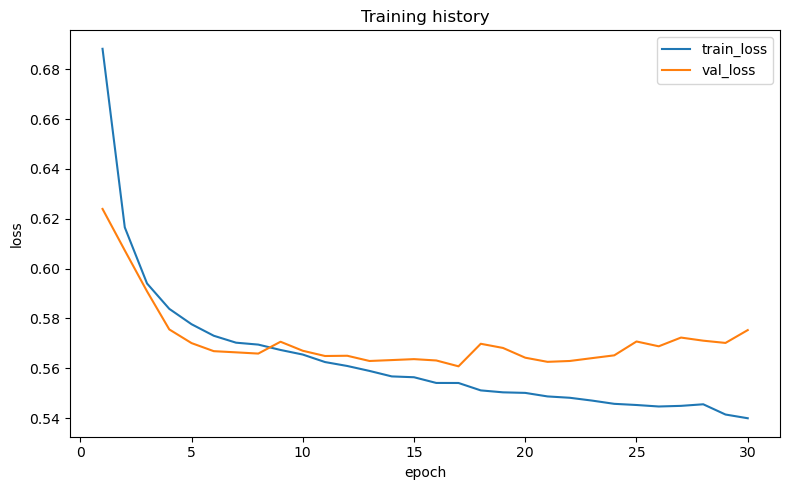

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/training_loss.png


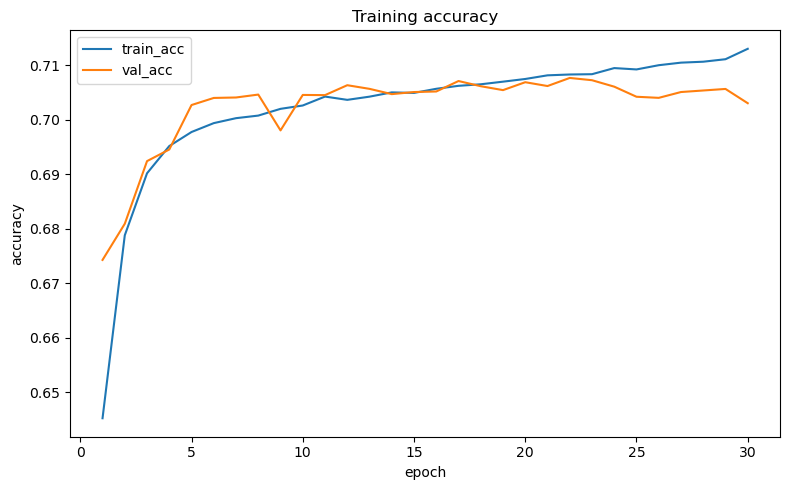

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/training_accuracy.png


In [15]:
hist = pd.DataFrame(history)
plt.figure(figsize=(8, 5))
plt.plot(hist['epoch'], hist['train_loss'], label='train_loss')
plt.plot(hist['epoch'], hist['val_loss'], label='val_loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Training history')
plt.legend()
plt.tight_layout()
out = FIGS / 'training_loss.png'
plt.savefig(out, dpi=150)
plt.show()
print('saved:', out)

plt.figure(figsize=(8, 5))
plt.plot(hist['epoch'], hist['train_acc'], label='train_acc')
plt.plot(hist['epoch'], hist['val_acc'], label='val_acc')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('Training accuracy')
plt.legend()
plt.tight_layout()
out = FIGS / 'training_accuracy.png'
plt.savefig(out, dpi=150)
plt.show()
print('saved:', out)

## Evaluation and embeddings

In [16]:
# Load best checkpoint
ckpt = torch.load(MODELS / 'linformer_nodes_aligned_best.pt', map_location=DEVICE)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

def predict_latents_logits(model, X: np.ndarray, batch_size: int = 2048):
    loader = DataLoader(
        TensorDatasetTorch(X, np.zeros(len(X), dtype=np.int64)),
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )
    latents = []
    logits = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(DEVICE)
            out = model(xb)
            latents.append(out['latent'].cpu().numpy())
            logits.append(out['logits'].cpu().numpy())
    return np.concatenate(latents, axis=0), np.concatenate(logits, axis=0)

Z_eval, logits_eval = predict_latents_logits(model, X_eval)
pred_eval = logits_eval.argmax(axis=1)
report_text = classification_report(y_eval, pred_eval, target_names=CLASS_NAMES)
report_dict = classification_report(y_eval, pred_eval, target_names=CLASS_NAMES, output_dict=True)
cm_eval = confusion_matrix(y_eval, pred_eval)
print(report_text)
print('Confusion matrix:')
print(cm_eval)

dy_idx = LABEL_MAP['dy']
minbias_idx = LABEL_MAP['minbias']
dy_total = cm_eval[dy_idx].sum()
dy_to_minbias = cm_eval[dy_idx, minbias_idx]
print(f'DY -> MinBias confusion: {dy_to_minbias:,}/{dy_total:,} ({dy_to_minbias / max(dy_total, 1):.1%})')

pd.DataFrame(report_dict).T.to_csv(PROJECT / 'classification_report_eval.csv')
pd.DataFrame(cm_eval, index=[f'true_{c}' for c in CLASS_NAMES], columns=[f'pred_{c}' for c in CLASS_NAMES]).to_csv(PROJECT / 'confusion_matrix_eval.csv')
np.save(PROJECT / 'eval_latents.npy', Z_eval)
np.save(PROJECT / 'eval_logits.npy', logits_eval)


              precision    recall  f1-score   support

     minbias       0.51      0.48      0.49     15000
         top       0.93      0.96      0.95     15000
         qcd       0.82      0.84      0.83     15000
          dy       0.55      0.56      0.55     15000

    accuracy                           0.71     60000
   macro avg       0.70      0.71      0.71     60000
weighted avg       0.70      0.71      0.71     60000

Confusion matrix:
[[ 7143     0  1204  6653]
 [    3 14377   613     7]
 [ 1212  1001 12603   184]
 [ 5670    46   921  8363]]
DY -> MinBias confusion: 5,670/15,000 (37.8%)


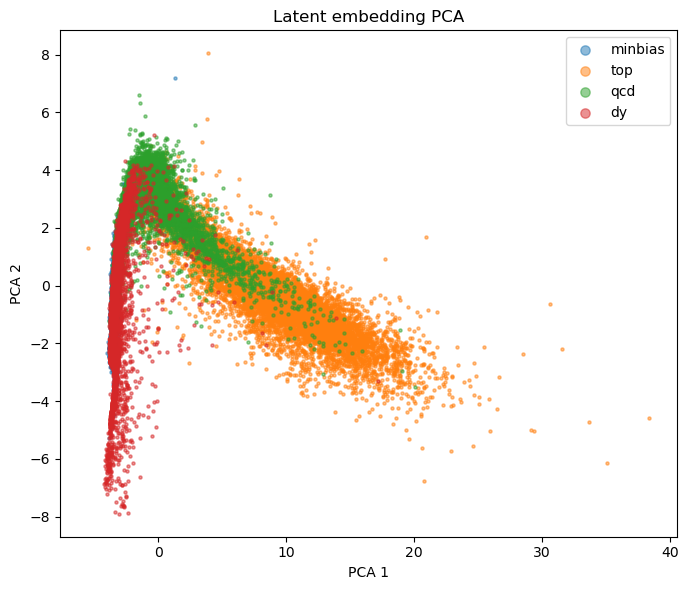

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/embedding_pca_eval.png


In [17]:
pca2 = PCA(n_components=2, random_state=SEED)
Z2 = pca2.fit_transform(Z_eval)

plt.figure(figsize=(7, 6))
for cls in CLASS_NAMES:
    m = y_eval == LABEL_MAP[cls]
    plt.scatter(Z2[m, 0], Z2[m, 1], s=5, alpha=0.5, label=cls)
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Latent embedding PCA')
plt.legend(markerscale=3)
plt.tight_layout()
out = FIGS / 'embedding_pca_eval.png'
plt.savefig(out, dpi=150)
plt.show()
print('saved:', out)

## Mahalanobis anomaly score

This follows the repository anomaly-score idea:

1. extract model latents,
2. fit PCA on normal-class latents,
3. fit empirical covariance in PCA space,
4. anomaly score = negative Gaussian log-probability, equivalent to a Mahalanobis-distance score plus normalization constants.

Here `MinBias` is the normal class by default.

In [18]:
# Fit on normal-class train latents only.
normal_train_mask = y_train == NORMAL_CLASS_IDX
Z_train_normal, _ = predict_latents_logits(model, X_train[normal_train_mask])

PCA_DIM = min(16, Z_train_normal.shape[1])
pca_maha = PCA(n_components=PCA_DIM, whiten=False, random_state=SEED)
Z_normal_pca = pca_maha.fit_transform(Z_train_normal)

cov = EmpiricalCovariance().fit(Z_normal_pca)
mu = cov.location_
Sigma = cov.covariance_ + 1e-6 * np.eye(PCA_DIM)
Sigma_inv = np.linalg.inv(Sigma)
sign, logdet = np.linalg.slogdet(Sigma)
D = PCA_DIM

def mahalanobis_negative_logprob(latents: np.ndarray) -> np.ndarray:
    Zp = pca_maha.transform(latents)
    diff = Zp - mu
    d2 = np.einsum('bi,ij,bj->b', diff, Sigma_inv, diff)
    log_prob = -0.5 * (d2 + logdet + D * np.log(2 * np.pi))
    return -log_prob.astype(np.float32)

maha_scores_eval = mahalanobis_negative_logprob(Z_eval)
np.save(PROJECT / 'mahalanobis_scores_eval.npy', maha_scores_eval)

summary = []
for cls in CLASS_NAMES:
    scores = maha_scores_eval[y_eval == LABEL_MAP[cls]]
    summary.append({
        'class': cls,
        'n': len(scores),
        'mean_score': float(np.mean(scores)),
        'std_score': float(np.std(scores)),
        'p50': float(np.percentile(scores, 50)),
        'p90': float(np.percentile(scores, 90)),
        'p95': float(np.percentile(scores, 95)),
        'p99': float(np.percentile(scores, 99)),
        'p99_5': float(np.percentile(scores, 99.5)),
        'p99_9': float(np.percentile(scores, 99.9)),
    })
summary_df = pd.DataFrame(summary)
summary_df.to_csv(PROJECT / 'mahalanobis_summary_eval.csv', index=False)
display(summary_df)


,class,n,mean_score,std_score,p50,p90,p95,p99,p99_5,p99_9
0,minbias,15000,-37.514534,77.869766,-43.658052,-34.271896,-23.140669,45.815785,99.012989,4.579120e+02
1,top,15000,173274.984375,154929.593750,133039.148438,370329.618750,469206.551562,697942.055000,806390.951250,1.107329e+06
2,qcd,15000,4429.852051,24974.494141,47.733664,3623.641260,15536.753564,106365.949297,167034.381641,3.433580e+05
3,dy,15000,428.050110,6430.868164,-43.844070,148.230962,811.138577,9857.579033,18370.608555,4.614386e+04


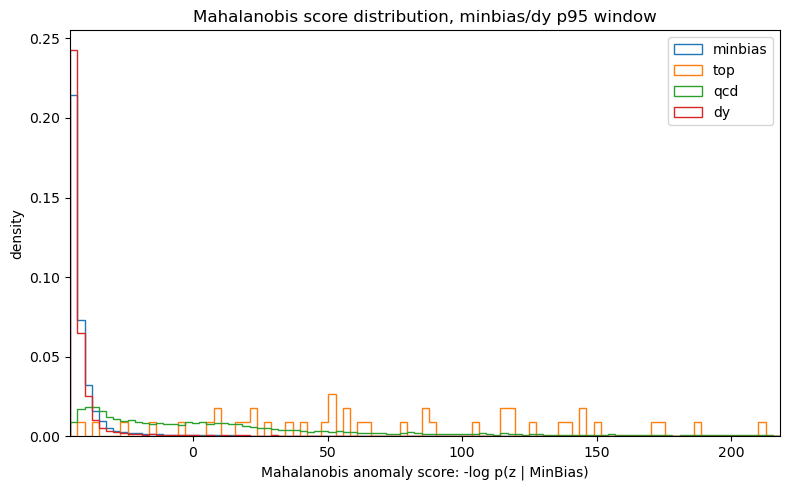

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/mahalanobis_scores_eval.png


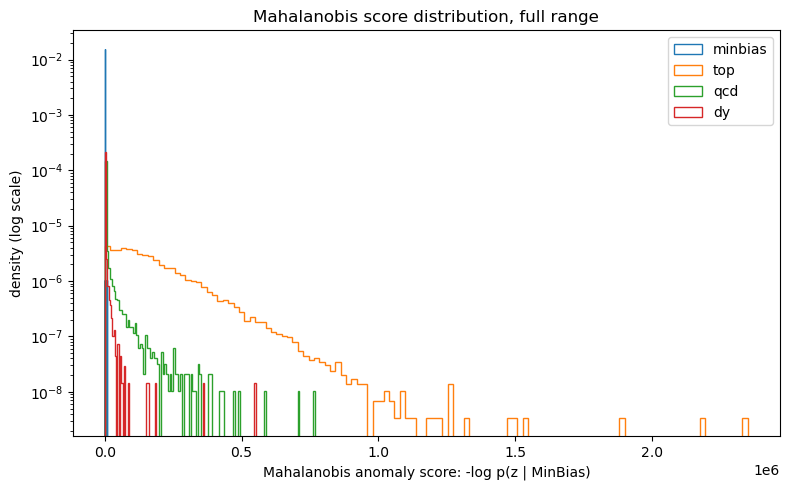

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/mahalanobis_scores_eval_logy_full_range.png


In [19]:
MAHA_FOCUS_CLASSES = ['minbias', 'dy']
MAHA_FOCUS_PERCENTILE = 95.0
focus_scores = np.concatenate([
    maha_scores_eval[y_eval == LABEL_MAP[cls]]
    for cls in MAHA_FOCUS_CLASSES
])
focus_scores = focus_scores[np.isfinite(focus_scores)]
clip_lo = float(np.percentile(focus_scores, 0.5))
clip_hi = float(np.percentile(focus_scores, MAHA_FOCUS_PERCENTILE))
bins = np.linspace(clip_lo, clip_hi, 100)

plt.figure(figsize=(8, 5))
for cls in CLASS_NAMES:
    scores = maha_scores_eval[y_eval == LABEL_MAP[cls]]
    scores = scores[np.isfinite(scores)]
    scores = scores[(scores >= clip_lo) & (scores <= clip_hi)]
    plt.hist(scores, bins=bins, histtype='step', density=True, label=cls)
plt.xlabel('Mahalanobis anomaly score: -log p(z | MinBias)')
plt.ylabel('density')
plt.title(f'Mahalanobis score distribution, {"/".join(MAHA_FOCUS_CLASSES)} p{MAHA_FOCUS_PERCENTILE:g} window')
plt.xlim(clip_lo, clip_hi)
plt.legend()
plt.tight_layout()
out = FIGS / 'mahalanobis_scores_eval.png'
plt.savefig(out, dpi=150)
plt.savefig(FIGS / f'mahalanobis_scores_eval_focus_minbias_dy_p{MAHA_FOCUS_PERCENTILE:g}.png', dpi=150)
plt.show()
print('saved:', out)

plt.figure(figsize=(8, 5))
for cls in CLASS_NAMES:
    scores = maha_scores_eval[y_eval == LABEL_MAP[cls]]
    scores = scores[np.isfinite(scores)]
    plt.hist(scores, bins=120, histtype='step', density=True, label=cls)
plt.xlabel('Mahalanobis anomaly score: -log p(z | MinBias)')
plt.ylabel('density (log scale)')
plt.title('Mahalanobis score distribution, full range')
plt.yscale('log')
plt.legend()
plt.tight_layout()
out_log = FIGS / 'mahalanobis_scores_eval_logy_full_range.png'
plt.savefig(out_log, dpi=150)
plt.show()
print('saved:', out_log)


## Outputs

Important files are saved under:

```text
ngt_linformer_nodes_aligned_outputs/
├── cache/                                 # shared raw tensor cache
└── runs/
    └── YYYY-MM-DD/                        # RUN_DATE, one folder per day
        └── n<events_per_class>_HHMMSS/    # RUN_LABEL, e.g. n1000_130744 or run1
            ├── figures/
            ├── models/
            ├── training_history.csv
            ├── eval_latents.npy
            ├── eval_logits.npy
            ├── mahalanobis_scores_eval.npy
            └── mahalanobis_summary_eval.csv
```

In [20]:
print('Output directory:', PROJECT)
print('Figures:')
for f in sorted(FIGS.glob('*.png')):
    print(' -', f)
print('Models:')
for f in sorted(MODELS.glob('*.pt')):
    print(' -', f)

Output directory: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843
Figures:
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/dy_minbias_event_feature_importance.png
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/dy_minbias_lepton_multiplicity.png
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/embedding_pca_eval.png
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_wide_attn_aug_n100000_143843/figures/mahalanobis_scores_eval.png
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_linformer_nodes_aligned_outputs/runs/2026-07-02/dy_minbias_w